# 实验5 Python数据变换与离散化
依据课程要求与教材例题运行。

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn import preprocessing
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from IPython.display import display
%matplotlib inline
np.set_printoptions(precision=6, suppress=True)
plt.rcParams['figure.figsize'] = (6, 3)
print('numpy', np.__version__, 'pandas', pd.__version__)
print('sklearn', sklearn.__version__)


numpy 2.3.5 pandas 2.3.3
sklearn 1.9.0


In [13]:
# 例3-33 数据的离差标准化
def MinMaxScale(data):
    return (data-data.min())/(data.max()-data.min())
x = np.array([[1., -1., 2.], [2., 0., 0.],
              [0., 1., -1.]])
x33 = MinMaxScale(x)
print('原始数据：'); print(x)
print('标准化结果：'); print(x33)
print('全局最小值、最大值：', x33.min(), x33.max())

原始数据：
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]
标准化结果：
[[0.666667 0.       1.      ]
 [1.       0.333333 0.333333]
 [0.333333 0.666667 0.      ]]
全局最小值、最大值： 0.0 1.0


In [14]:
# 例3-34 数据的标准差标准化
def StandardScale(data):
    return (data-data.mean())/data.std()
x34 = StandardScale(x)
print('原始数据：'); print(x)
print('标准化结果：'); print(x34)
print('全局均值、标准差：', x34.mean(), x34.std())

原始数据：
[[ 1. -1.  2.]
 [ 2.  0.  0.]
 [ 0.  1. -1.]]
标准化结果：
[[ 0.521286 -1.355344  1.459601]
 [ 1.459601 -0.417029 -0.417029]
 [-0.417029  0.521286 -1.355344]]
全局均值、标准差： 0.0 1.0


In [15]:
# 例3-36 PCA将鸢尾花数据从4维降至2维
from sklearn.decomposition import PCA
data = load_iris()
y = data.target
iris_x = data.data
pca = PCA(n_components=2)
reduced_x = pca.fit_transform(iris_x)
print('降维前后形状：', iris_x.shape, reduced_x.shape)
print('前5个样本：'); print(reduced_x[:5])
print('方差解释比例：', pca.explained_variance_ratio_)
print('累计比例：', pca.explained_variance_ratio_.sum())

降维前后形状： (150, 4) (150, 2)
前5个样本：
[[-2.684126  0.319397]
 [-2.714142 -0.177001]
 [-2.888991 -0.144949]
 [-2.745343 -0.318299]
 [-2.728717  0.326755]]
方差解释比例： [0.924619 0.053066]
累计比例： 0.9776852063187963


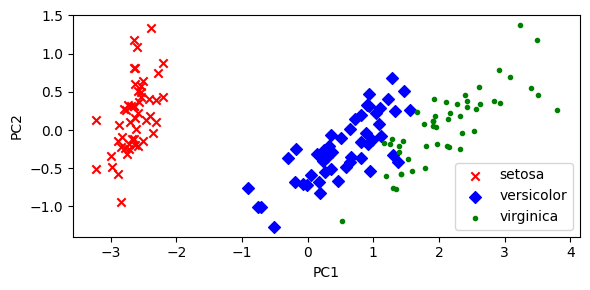

In [16]:
# 例3-36 降维后的样本点分布
for label, color, marker in [(0,'r','x'), (1,'b','D'),
                              (2,'g','.')]:
    pts = reduced_x[y == label]
    plt.scatter(pts[:, 0], pts[:, 1], c=color,
                marker=marker, label=data.target_names[label])
plt.xlabel('PC1'); plt.ylabel('PC2')
plt.legend(); plt.tight_layout(); plt.show()

In [17]:
# 例3-37 按列进行数据规范化
a = [47, 83, 81, 18, 72, 41]
b = [56, 96, 84, 21, 87, 67]
dfab = pd.DataFrame(np.array([a, b]).T,
                    columns=['A', 'B'])
minmax37 = (dfab-dfab.min())/(dfab.max()-dfab.min())
zscore37 = (dfab-dfab.mean())/dfab.std()
print('最小最大规范化：'); print(minmax37)
print('零均值规范化：'); print(zscore37)
print('均值：', zscore37.mean().to_numpy())
print('样本标准差：', zscore37.std().to_numpy())

最小最大规范化：
          A         B
0  0.446154  0.466667
1  1.000000  1.000000
2  0.969231  0.840000
3  0.000000  0.000000
4  0.830769  0.880000
5  0.353846  0.613333
零均值规范化：
          A         B
0 -0.386103 -0.456223
1  1.003868  1.003690
2  0.926648  0.565716
3 -1.505803 -1.733646
4  0.579155  0.675209
5 -0.617765 -0.054747
均值： [0. 0.]
样本标准差： [1. 1.]


In [18]:
# 例3-38 对类别数据进行哑变量处理
df = pd.DataFrame([
    ['green', 'M', 10.1, 'class1'],
    ['red', 'L', 13.5, 'class2'],
    ['blue', 'XL', 14.3, 'class1']],
    columns=['color', 'size', 'prize', 'class label'])
dummies38 = pd.get_dummies(df, dtype=int)
print('原始表：'); display(df)
print('哑变量表形状：', dummies38.shape)
print('转置显示，便于逐列核对：')
display(dummies38.T)

原始表：


,color,size,prize,class label
0,green,M,10.1,class1
1,red,L,13.5,class2
2,blue,XL,14.3,class1


哑变量表形状： (3, 9)
转置显示，便于逐列核对：


,0,1,2
prize,10.1,13.5,14.3
color_blue,0.0,0.0,1.0
color_green,1.0,0.0,0.0
color_red,0.0,1.0,0.0
size_L,0.0,1.0,0.0
size_M,1.0,0.0,0.0
size_XL,0.0,0.0,1.0
class label_class1,1.0,0.0,1.0
class label_class2,0.0,1.0,0.0


In [19]:
# 例3-39 指定区间进行分箱
np.random.seed(666)
score_list = np.random.randint(25, 100, size=10)
bins = [0, 59, 70, 80, 100]
score_cut = pd.cut(score_list, bins)
print('原始成绩：', score_list)
print('按区间顺序统计：')
print(score_cut.value_counts())

原始成绩： [27 70 55 87 95 98 55 61 86 76]
按区间顺序统计：
(0, 59]      3
(59, 70]     2
(70, 80]     1
(80, 100]    4
Name: count, dtype: int64


In [20]:
# 例3-40 运行教材中的原始写法
def SameRateCut(data, k):
    k = 2
    w = data.quantile(np.arange(0, 1+1.0/k, 1.0/k))
    return pd.cut(data, w)
result40_old = SameRateCut(pd.Series(score_list), 3)
print('教材写法的分箱统计：')
print(result40_old.value_counts())
print('未入箱数量：', result40_old.isna().sum())

教材写法的分箱统计：


(73.0, 98.0]    5
(27.0, 73.0]    4
Name: count, dtype: int64
未入箱数量： 1


In [21]:
# 例3-40 按传入k分箱，并包含最小值
def SameRateCutFixed(data, k):
    w = data.quantile(np.linspace(0, 1, k+1)).round(12)
    return pd.cut(data, w, include_lowest=True)
result40 = SameRateCutFixed(pd.Series(score_list), 3)
print('修正后的3箱统计：')
print(result40.value_counts(sort=False))
print('未入箱数量：', result40.isna().sum())

修正后的3箱统计：
(26.999, 61.0]    4
(61.0, 86.0]      3
(86.0, 98.0]      3
Name: count, dtype: int64
未入箱数量： 0


In [22]:
# 结果校验
assert np.allclose([x33.min(), x33.max()], [0, 1])
assert np.allclose([x34.mean(), x34.std()], [0, 1])
assert reduced_x.shape == (150, 2)
assert pca.explained_variance_ratio_.sum() > .97
assert np.allclose(zscore37.mean(), 0)
assert np.allclose(zscore37.std(), 1)
assert dummies38.shape == (3, 9)
assert score_cut.value_counts().tolist() == [3, 2, 1, 4]
assert result40_old.isna().sum() == 1
assert result40.value_counts(sort=False).tolist() == [4, 3, 3]
assert result40.isna().sum() == 0
print('实验五7个例题全部运行；范围、统计量、形状及分箱结果校验通过。')

实验五7个例题全部运行；范围、统计量、形状及分箱结果校验通过。
